CELL 1 — IMPORT LIBRARY

In [1]:
import json
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import Workbook, load_workbook
from google.colab import files

warnings.filterwarnings("ignore")

print("✅ Library siap.")

✅ Library siap.


CELL 2 — FUNGSI INTI SVR DAN PREPROCESSING

In [2]:
"""Kernel RBF untuk vektor — Persamaan 2.15."""
def kernel_rbf_vec(xi: np.ndarray, xj: np.ndarray,gamma: float) -> float:
    diff = xi - xj
    return float(np.exp(-gamma * np.dot(diff, diff)))

"""Prediksi jarak — Persamaan 2.16."""
def prediksi_svr_vec(x_test: np.ndarray, X_train: np.ndarray, alpha_diff: np.ndarray, b: float, gamma: float) -> float:
    kvals = np.array([kernel_rbf_vec(X_train[i], x_test, gamma)
                      for i in range(len(X_train))])
    return float(np.dot(alpha_diff, kvals) + b)

"""Gaussian Filter — Persamaan 3.1, 3.2, 2.3, 3.3, 3.4."""
def gaussian_filter(rssi_array: np.ndarray, k: float = 1.0, q_threshold: float = 0.5) -> dict:
    n = len(rssi_array)
    k_used = k

    while True:
        xe = np.mean(rssi_array)
        omega = np.sqrt(np.mean((rssi_array - xe) ** 2))
        mask = np.abs(rssi_array - xe) < k_used * omega
        data_bersih = rssi_array[mask]
        P = (len(data_bersih) / n) * 100

        if P >= q_threshold * 100 or k_used >= 3:
            break
        k_used += 1

    xe_bersih = np.mean(data_bersih)
    return {"xe_bersih": xe_bersih, "data_bersih": data_bersih}

"""Kalman Filter — Persamaan 2.4 s/d 2.9."""
def kalman_filter(rssi_array: np.ndarray, phi: float = 1.0, Q: float = 0.01,
                  Rv: float = 0.1, P0: float = 1.0) -> float:
    x_est, P_est = rssi_array[0], P0

    for zk in rssi_array:
        x_pred = phi * x_est
        P_pred = (phi * P_est * phi) + Q
        Kk = P_pred / (P_pred + Rv)
        x_est = x_pred + Kk * (zk - x_pred)
        P_est = (1 - Kk) * P_pred

    return float(x_est)

"""Pipeline Gaussian → Kalman, return xk_final."""
def preprocessing(rssi_array: np.ndarray) -> float:
    hasil_gaussian = gaussian_filter(rssi_array)
    return kalman_filter(hasil_gaussian["data_bersih"])

print("✅ Fungsi SVR dan preprocessing siap.")

✅ Fungsi SVR dan preprocessing siap.


CELL 3 — UPLOAD SEMUA FILE

In [15]:
"""
Upload :
  1. model_svr_landmarc_*.json          → model baseline LOS
  2. data_*_NLOS_*_Referensi_*.xlsx     → referensi NLOS
     Skenario 1: 3 file (Sedikit, Sedang, Banyak)
     Skenario 2: 3 file (Sedikit, Sedang, Banyak)
  3. data_*_NLOS_*_Target_*cm_*.xlsx    → target NLOS
     Format baru: sheet Target + R1 + R2 (+ R3 untuk Skenario 2)
"""
print("Upload semua file sekaligus:")
print("  1. model_svr_landmarc_*.json")
print("  2. data_*_NLOS_*_Referensi_*.xlsx")
print("     (3 file: sedikit/sedang/banyak)")
print("  3. data_*_NLOS_*_Target_*cm_*.xlsx")
print("     Skenario 1: sheet Target + R1 + R2")
print("     Skenario 2: sheet Target + R1 + R2 + R3")
print()

uploaded = files.upload()
filenames = list(uploaded.keys())

model_files = [f for f in filenames if f.endswith(".json")]
ref_files = [f for f in filenames if "Referensi" in f and f.endswith(".xlsx")]
target_files = [f for f in filenames if "Target" in f and f.endswith(".xlsx")]

print(f"\n✅ Model files  : {model_files}")
print(f"✅ Ref NLOS     : {ref_files}")
print(f"✅ Target NLOS  : {target_files}")

Upload semua file sekaligus:
  1. model_svr_landmarc_*.json
  2. data_*_NLOS_*_Referensi_*.xlsx
     (3 file: sedikit/sedang/banyak)
  3. data_*_NLOS_*_Target_*cm_*.xlsx
     Skenario 1: sheet Target + R1 + R2
     Skenario 2: sheet Target + R1 + R2 + R3



Saving data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx to data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx to data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx to data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx to data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx to data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx to data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx to data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx
Saving data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx to data_Skenario2_NLO

CELL 4 — LOAD MODEL BASELINE LOS

In [16]:
def load_model(json_file: str) -> dict:
    with open(json_file, "r") as f:
        raw = json.load(f)

    models = {}

    for nama, p in raw.items():
        models[nama] = {
            "gamma": p["gamma"],
            "C": p["C"],
            "epsilon": p["epsilon"],
            "b": p["b"],
            "alpha_diff": np.array(p["alpha_diff"]),
            "X_train": np.array(p["X_train"]),
            "y_train": np.array(p["y_train"]),
            "urutan_ref": p["urutan_ref"],
            "kondisi": p["kondisi"],
            "n_fitur": p["n_fitur"],
            "jarak_training_cm": p.get("jarak_training_cm", []),
            "jarak_ref_per_tag": p.get("jarak_ref_m", {}),
        }

    return models

model_baseline = {}

for mf in model_files:
    model_baseline.update(load_model(mf))

print("✅ Model baseline LOS dimuat:")

for nama, model in model_baseline.items():
    refs = "+".join(model["urutan_ref"]) + "+Target"
    print(f"\n  {nama}:")
    print(f"  ├─ γ={model['gamma']}, C={model['C']}, ε={model['epsilon']}")
    print(f"  ├─ b baseline = {model['b']:.6f}")
    print(f"  ├─ Input = {model['n_fitur']}D [{refs}]")
    print(f"  ├─ Training pada jarak = {model['jarak_training_cm']} cm")
    print(f"  └─ Jarak referensi = {model['jarak_ref_per_tag']}")

✅ Model baseline LOS dimuat:

  Skenario2:
  ├─ γ=0.01, C=10, ε=0.001
  ├─ b baseline = 1.304405
  ├─ Input = 4D [R1+R2+R3+Target]
  ├─ Training pada jarak = [80, 100, 140, 170] cm
  └─ Jarak referensi = {'R1': 0.5, 'R2': 1.25, 'R3': 2.0}


CELL 5 — PREPROCESSING DATA REFERENSI NLOS

In [17]:
def deteksi_kondisi_nlos(fname: str) -> str:
    condition_map = {
        "NLOS_Sedikit": "NLOS_Satu_Halangan",
        "NLOS_Sedang": "NLOS_Tiga_Halangan",
        "NLOS_Banyak": "NLOS_Lima_Halangan",
    }

    fname_norm = fname.replace("_", "").lower()

    for nama_file, kondisi_baru in condition_map.items():
        if nama_file.replace("_", "").lower() in fname_norm:
            return kondisi_baru

    return "NLOS_Satu_Halangan"

def baca_referensi_nlos(filelist: list) -> dict:
    hasil = {}

    for fname in filelist:
        wb = load_workbook(fname)
        parts = fname.replace(".xlsx", "").split("_")
        skenario = next((p for p in parts if "Skenario" in p), "Skenario1")
        kondisi = deteksi_kondisi_nlos(fname)

        hasil.setdefault(skenario, {}).setdefault(kondisi, {})

        for sheet_name in wb.sheetnames:
            if sheet_name.lower() == "ringkasan":
                continue

            rows = list(wb[sheet_name].iter_rows(values_only=True))

            if len(rows) < 2:
                continue

            df = pd.DataFrame(rows[1:], columns=rows[0])
            df["RSSI (dBm)"] = pd.to_numeric(df["RSSI (dBm)"], errors="coerce")
            df = df.dropna(subset=["RSSI (dBm)"])

            if not df.empty:
                hasil[skenario][kondisi][sheet_name] = preprocessing(
                    df["RSSI (dBm)"].values
                )

    return hasil

print("=" * 60)
print("  PREPROCESSING DATA REFERENSI NLOS")
print("=" * 60)

xk_ref_nlos = baca_referensi_nlos(ref_files)

for skenario, kondisi_dict in xk_ref_nlos.items():
    print(f"\n📋 {skenario}:")
    model = model_baseline.get(skenario, {})

    for kondisi, tag_dict in kondisi_dict.items():
        print(f"\n  {kondisi}:")
        print(f"  {'Tag':<6} {'xk LOS':>12} {'xk NLOS':>12} {'ΔRSSI':>12}")
        print(f"  {'-' * 6} {'-' * 12} {'-' * 12} {'-' * 12}")

        for tag in model.get("urutan_ref", []):
            if model:
                ref_idx = model["urutan_ref"].index(tag)
                xk_los = float(np.mean(model["X_train"][:, ref_idx]))
            else:
                xk_los = 0.0

            xk_nlos = tag_dict.get(tag, xk_los)
            delta = xk_nlos - xk_los

            print(f"  {tag:<6} {xk_los:>12.5f} {xk_nlos:>12.5f} {delta:>12.5f} dBm")

print("\n✅ Preprocessing referensi NLOS selesai.")

  PREPROCESSING DATA REFERENSI NLOS

📋 Skenario2:

  NLOS_Lima_Halangan:
  Tag          xk LOS      xk NLOS        ΔRSSI
  ------ ------------ ------------ ------------
  R1        -42.25000    -53.00000    -10.75000 dBm
  R2        -51.28218    -59.09457     -7.81238 dBm
  R3        -60.73392    -67.00000     -6.26608 dBm

  NLOS_Tiga_Halangan:
  Tag          xk LOS      xk NLOS        ΔRSSI
  ------ ------------ ------------ ------------
  R1        -42.25000    -51.00000     -8.75000 dBm
  R2        -51.28218    -56.34980     -5.06761 dBm
  R3        -60.73392    -64.09826     -3.36434 dBm

  NLOS_Satu_Halangan:
  Tag          xk LOS      xk NLOS        ΔRSSI
  ------ ------------ ------------ ------------
  R1        -42.25000    -45.00000     -2.75000 dBm
  R2        -51.28218    -53.00000     -1.71782 dBm
  R3        -60.73392    -62.00000     -1.26608 dBm

✅ Preprocessing referensi NLOS selesai.


CELL 6 — MEKANISME ADAPTASI SVR-LANDMARC

In [18]:
"""
  Mekanisme adaptasi menggunakan KOREKSI VEKTOR INPUT
  dengan metode WEIGHTED INVERSE DISTANCE:

  Persamaan 3.6: ΔRSSI_i = xk_NLOS_i - xk_LOS_i  (per tag ref)
  Persamaan 3.7: ΔRSSI_berbobot = Σ(wi × ΔRSSI_i)

  Bobot wi dihitung berdasarkan kedekatan jarak target ke referensi:
    wi = (1 / |d_target - d_ref_i| + ε) / Σ(1 / |d_target - d_ref_j| + ε)

  Tag referensi yang lebih dekat ke target mendapat bobot lebih besar
  karena kondisi propagasi sinyalnya lebih merepresentasikan
  lingkungan di sekitar target.

  Koreksi vektor:
    komponen_ref[i]  -= ΔRSSI_i          (Persamaan 3.6)
    komponen_target  -= ΔRSSI_berbobot   (Persamaan 3.7)
"""

def adaptasi_model(model_baseline: dict, xk_nlos_per_tag: dict) -> dict:
    """
    Adaptasi untuk kondisi NLOS.
    Menyimpan parameter koreksi vektor input.
    Model SVR (alpha_diff, b, X_train) TIDAK berubah.
    """
    urutan_ref = model_baseline["urutan_ref"]
    X_train = model_baseline["X_train"]

    # Ambil xk LOS dari rata-rata komponen referensi di X_train
    xk_los_per_tag = {
        tag: float(np.mean(X_train[:, ref_idx]))
        for ref_idx, tag in enumerate(urutan_ref)
    }

    # Persamaan 3.6 — ΔRSSI per tag referensi
    delta_rssi = {}
    for tag in urutan_ref:
        xk_los  = xk_los_per_tag[tag]
        xk_nlos = xk_nlos_per_tag.get(tag, xk_los)
        delta_rssi[tag] = xk_nlos - xk_los

    return {
        # Parameter SVR TIDAK berubah
        'gamma'            : model_baseline['gamma'],
        'C'                : model_baseline['C'],
        'epsilon'          : model_baseline['epsilon'],
        'b'                : model_baseline['b'],
        'alpha_diff'       : model_baseline['alpha_diff'],
        'X_train'          : X_train,
        'y_train'          : model_baseline['y_train'],
        'urutan_ref'       : urutan_ref,
        'n_fitur'          : model_baseline['n_fitur'],
        # Parameter koreksi vektor input
        "delta_rssi": delta_rssi,
        "xk_los_per_tag": xk_los_per_tag,
        "xk_nlos_per_tag": xk_nlos_per_tag,
        "jarak_ref_per_tag": model_baseline.get("jarak_ref_per_tag", {}),
    }


def koreksi_vektor_input(vektor_nlos: np.ndarray, model_adaptif: dict,
                          jarak_target_m: float) -> np.ndarray:
    """
    Koreksi vektor input NLOS ke skala LOS menggunakan
    Weighted Inverse Distance.

    Komponen referensi dikurangi ΔRSSI masing-masing (Pers. 3.6).
    Komponen target dikurangi ΔRSSI berbobot (Pers. 3.7).

    Bobot = inverse distance antara jarak target dan referensi.
    Tag referensi lebih dekat ke target → bobot lebih besar.
    """
    urutan_ref     = model_adaptif['urutan_ref']
    xk_los_per_tag = model_adaptif['xk_los_per_tag']
    jarak_ref      = model_adaptif.get('jarak_ref_per_tag', {})
    vektor_adj     = vektor_nlos.copy().astype(float)

    # Hitung ΔRSSI dari R1/R2 yang terbaca bersamaan target
    delta_per_ref = {}
    for ref_idx, tag in enumerate(urutan_ref):
        xk_los_ref          = xk_los_per_tag[tag]
        xk_nlos_ref         = vektor_nlos[ref_idx]
        delta_per_ref[tag]  = xk_nlos_ref - xk_los_ref
        # Koreksi komponen referensi — Persamaan 3.6
        vektor_adj[ref_idx] -= delta_per_ref[tag]

    # Hitung bobot weighted inverse distance
    bobot = {}
    for tag in urutan_ref:
        d_ref      = jarak_ref.get(tag, 1.0)
        dist       = abs(jarak_target_m - d_ref)
        bobot[tag] = 1.0 / (dist + 0.01)

    # Normalisasi bobot
    total_bobot = sum(bobot.values())
    for tag in bobot:
        bobot[tag] /= total_bobot

    # Koreksi komponen target — Persamaan 3.7
    delta_target   = sum(bobot[tag] * delta_per_ref[tag] for tag in urutan_ref)
    vektor_adj[-1] -= delta_target

    return vektor_adj


print("="*60)
print("  MEKANISME ADAPTASI — WEIGHTED INVERSE DISTANCE")
print("="*60)

model_adaptif = {}

for skenario, kondisi_dict in xk_ref_nlos.items():
    model_adaptif[skenario] = {}
    baseline = model_baseline.get(skenario)
    if not baseline:
        print(f"⚠️  Tidak ada model baseline untuk {skenario}")
        continue

    print(f"\n📋 {skenario}:")
    for kondisi, xk_nlos_per_tag in kondisi_dict.items():
        m_baru = adaptasi_model(baseline, xk_nlos_per_tag)
        model_adaptif[skenario][kondisi] = m_baru

        print(f"\n  ── {kondisi} ──")
        print(f"  {'Tag':<6} {'xk LOS':>10} {'xk NLOS':>10} " f"{'ΔRSSI':>10} {'Jarak Ref':>10}")
        print(f"  {'-'*6} {'-'*10} {'-'*10} {'-'*10} {'-'*10}")

        for tag in baseline['urutan_ref']:
            xk_los  = m_baru['xk_los_per_tag'].get(tag, 0)
            xk_nlos = m_baru['xk_nlos_per_tag'].get(tag, 0)
            delta   = m_baru['delta_rssi'].get(tag, 0)
            jarak_r = m_baru['jarak_ref_per_tag'].get(tag, '-')

            print(
                f"  {tag:<6} {xk_los:>10.4f} {xk_nlos:>10.4f} "
                f"{delta:>10.4f} dBm {str(jarak_r):>8}m"
            )

print("\n✅ Adaptasi model selesai.")

  MEKANISME ADAPTASI — WEIGHTED INVERSE DISTANCE

📋 Skenario2:

  ── NLOS_Lima_Halangan ──
  Tag        xk LOS    xk NLOS      ΔRSSI  Jarak Ref
  ------ ---------- ---------- ---------- ----------
  R1       -42.2500   -53.0000   -10.7500 dBm      0.5m
  R2       -51.2822   -59.0946    -7.8124 dBm     1.25m
  R3       -60.7339   -67.0000    -6.2661 dBm      2.0m

  ── NLOS_Tiga_Halangan ──
  Tag        xk LOS    xk NLOS      ΔRSSI  Jarak Ref
  ------ ---------- ---------- ---------- ----------
  R1       -42.2500   -51.0000    -8.7500 dBm      0.5m
  R2       -51.2822   -56.3498    -5.0676 dBm     1.25m
  R3       -60.7339   -64.0983    -3.3643 dBm      2.0m

  ── NLOS_Satu_Halangan ──
  Tag        xk LOS    xk NLOS      ΔRSSI  Jarak Ref
  ------ ---------- ---------- ---------- ----------
  R1       -42.2500   -45.0000    -2.7500 dBm      0.5m
  R2       -51.2822   -53.0000    -1.7178 dBm     1.25m
  R3       -60.7339   -62.0000    -1.2661 dBm      2.0m

✅ Adaptasi model selesai.


CELL 7 — PREPROCESSING DATA TARGET NLOS

In [19]:
def baca_target_nlos(filelist: list, urutan_ref: list) -> list:
    """
    Baca file target NLOS format baru.
    Sheet: Target + R1 + R2 (+ R3 untuk Skenario 2)
    Vektor input = [xk_R1_NLOS, xk_R2_NLOS, ..., xk_Target_NLOS]
    """
    hasil = []

    for fname in filelist:
        wb = load_workbook(fname)
        kondisi = deteksi_kondisi_nlos(fname)
        data_per_sheet = {}

        for sheet_name in wb.sheetnames:
            if sheet_name.lower() == "ringkasan":
                continue

            rows = list(wb[sheet_name].iter_rows(values_only=True))

            if len(rows) < 2:
                continue

            df = pd.DataFrame(rows[1:], columns=rows[0])
            df["RSSI (dBm)"] = pd.to_numeric(df["RSSI (dBm)"], errors="coerce")
            df = df.dropna(subset=["RSSI (dBm)"])

            if not df.empty:
                data_per_sheet[sheet_name] = df

        if "Target" not in data_per_sheet:
            print(f"⚠️ Sheet 'Target' tidak ada di {fname}")
            continue

        df_target = data_per_sheet["Target"]
        jarak_aktual_m = float(df_target["Jarak Aktual (cm)"].iloc[0]) / 100.0
        skenario = str(df_target["Skenario"].iloc[0]) if "Skenario" in df_target.columns else ""

        xk_target = preprocessing(df_target["RSSI (dBm)"].values)

        xk_refs = {}

        for ref_name in urutan_ref:
            if ref_name in data_per_sheet:
                xk_refs[ref_name] = preprocessing(data_per_sheet[ref_name]["RSSI (dBm)"].values)
            else:
                print(f"⚠️ Sheet '{ref_name}' tidak ada di {fname}")
                xk_refs[ref_name] = 0.0

        vektor = [xk_refs[ref] for ref in urutan_ref] + [xk_target]

        hasil.append({
            "jarak_aktual_m": jarak_aktual_m,
            "xk_target": xk_target,
            "xk_refs": xk_refs,
            "vektor_input": np.array(vektor),
            "kondisi": kondisi,
            "skenario": skenario,
        })

    hasil.sort(key=lambda x: (x["kondisi"], x["jarak_aktual_m"]))
    return hasil


print("=" * 60)
print("  PREPROCESSING DATA TARGET NLOS")
print("=" * 60)

nama_skenario = list(model_baseline.keys())[0]
urutan_ref = model_baseline[nama_skenario]["urutan_ref"]
data_target_nlos = baca_target_nlos(target_files, urutan_ref)

prev_kondisi = ""

for data in data_target_nlos:
    if data["kondisi"] != prev_kondisi:
        print(f"\n📋 {data['kondisi']}:")
        header_vec = "[" + ", ".join(urutan_ref) + ", Target]"
        print(f"  {'Jarak':>8}  Vektor Input {header_vec}")
        print(f"  {'-' * 8}  {'-' * 50}")
        prev_kondisi = data["kondisi"]

    vec_str = ", ".join(f"{v:.4f}" for v in data["vektor_input"])
    print(f"  {data['jarak_aktual_m'] * 100:>6.0f}cm  [{vec_str}]")

print(f"\n✅ {len(data_target_nlos)} file target NLOS dipreprocessing.")

  PREPROCESSING DATA TARGET NLOS

📋 NLOS_Lima_Halangan:
     Jarak  Vektor Input [R1, R2, R3, Target]
  --------  --------------------------------------------------
      80cm  [-53.0000, -59.0000, -67.5569, -58.0000]
      90cm  [-53.0000, -60.0000, -66.5631, -61.0000]
     100cm  [-53.0000, -60.0000, -67.7605, -59.0000]
     110cm  [-53.0000, -60.0000, -66.2799, -60.8228]
     140cm  [-53.0000, -59.0000, -67.5642, -65.9949]
     170cm  [-53.0000, -60.0000, -66.5046, -67.0000]

📋 NLOS_Satu_Halangan:
     Jarak  Vektor Input [R1, R2, R3, Target]
  --------  --------------------------------------------------
      80cm  [-44.0000, -54.0000, -62.0000, -48.0000]
      90cm  [-45.0000, -53.0000, -61.5458, -51.0000]
     100cm  [-44.0000, -53.0000, -62.0000, -53.0000]
     110cm  [-45.0000, -53.0000, -62.9435, -54.0000]
     140cm  [-45.0000, -52.0000, -63.0000, -55.0000]
     170cm  [-45.0000, -52.0000, -63.0000, -59.9896]

📋 NLOS_Tiga_Halangan:
     Jarak  Vektor Input [R1, R2, R3, Target

CELL 8 — PENGUJIAN MODEL ADAPTIF NLOS

In [20]:
def pembulatan_cm(nilai_m: float) -> int:
    return int(np.floor(nilai_m * 100 + 0.5))

print("=" * 60)
print("  PENGUJIAN MODEL SVR-LANDMARC ADAPTIF (NLOS)")
print("=" * 60)

hasil_nlos = {}

for skenario, kondisi_dict in model_adaptif.items():
    hasil_nlos[skenario] = {}

    for kondisi, model in kondisi_dict.items():
        data_filtered = [
            data for data in data_target_nlos
            if kondisi.lower() in data["kondisi"].lower()
            and skenario.lower() in data["skenario"].lower()
        ]

        if not data_filtered:
            print(f"⚠️ Tidak ada data: {skenario} | {kondisi}")
            continue

        print(f"\n📋 {skenario} — {kondisi}:")
        print(
            f"  {'Jarak':>8} {'Vektor NLOS':>28} "
            f"{'Vektor Koreksi':>28} {'Prediksi':>10} {'Error':>10}"
        )
        print(
            f"  {'-' * 8} {'-' * 28} {'-' * 28} "
            f"{'-' * 10} {'-' * 10}"
        )

        hasil_per_target = []

        for data in data_filtered:
            # Vektor NLOS
            vektor_nlos = data["vektor_input"]

            # Koreksi vektor
            vektor_adj = koreksi_vektor_input(
                vektor_nlos, model, jarak_target_m=data["jarak_aktual_m"]
            )

            # Prediksi model dalam meter
            jarak_pred_m = prediksi_svr_vec(
                vektor_adj, model["X_train"],
                model["alpha_diff"], model["b"], model["gamma"]
            )

            # Jarak aktual dan prediksi dalam cm
            jarak_aktual_cm = pembulatan_cm(data["jarak_aktual_m"])
            jarak_pred_cm = pembulatan_cm(jarak_pred_m)
            error_cm = abs(jarak_aktual_cm - jarak_pred_cm)

            v_nlos_str = str(np.round(vektor_nlos, 2).tolist())
            v_adj_str = str(np.round(vektor_adj, 2).tolist())

            print(
                f"  {jarak_aktual_cm:>6}cm  {v_nlos_str:>28}  "
                f"{v_adj_str:>28}  {jarak_pred_cm:>8}cm  {error_cm:>8}cm"
            )

            hasil_per_target.append({
                "jarak_aktual_m": jarak_aktual_cm / 100.0,
                "jarak_aktual_cm": jarak_aktual_cm,
                "vektor_input": vektor_nlos,
                "vektor_koreksi": vektor_adj,
                "jarak_prediksi_m_raw": jarak_pred_m,
                "jarak_prediksi_cm_raw": jarak_pred_m * 100,
                "jarak_prediksi_m": jarak_pred_cm / 100.0,
                "jarak_prediksi_cm": jarak_pred_cm,
                "error_m": error_cm / 100.0,
                "error_cm": error_cm,
            })

        y_act_cm = np.array([r["jarak_aktual_cm"] for r in hasil_per_target], dtype=float)
        y_pred_cm = np.array([r["jarak_prediksi_cm"] for r in hasil_per_target], dtype=float)
        error_cm_arr = np.abs(y_pred_cm - y_act_cm)

        mae_cm = float(np.mean(error_cm_arr))
        rmse_cm = float(np.sqrt(np.mean(error_cm_arr ** 2)))

        hasil_nlos[skenario][kondisi] = {
            "hasil_per_target": hasil_per_target,
            "mae_m": mae_cm / 100.0,
            "mae_cm": mae_cm,
            "rmse_m": rmse_cm / 100.0,
            "rmse_cm": rmse_cm,
        }

        print("\n  ┌──────────────────────┐")
        print(f"  │  MAE  = {mae_cm:>8.2f} cm  │")
        print(f"  │  RMSE = {rmse_cm:>8.2f} cm  │")
        print("  └──────────────────────┘")

print("\n✅ Pengujian NLOS selesai.")

  PENGUJIAN MODEL SVR-LANDMARC ADAPTIF (NLOS)

📋 Skenario2 — NLOS_Lima_Halangan:
     Jarak                  Vektor NLOS               Vektor Koreksi   Prediksi      Error
  -------- ---------------------------- ---------------------------- ---------- ----------
      80cm  [-53.0, -59.0, -67.56, -58.0]  [-42.25, -51.28, -60.73, -48.83]        87cm         7cm
      90cm  [-53.0, -60.0, -66.56, -61.0]  [-42.25, -51.28, -60.73, -51.9]       106cm        16cm
     100cm  [-53.0, -60.0, -67.76, -59.0]  [-42.25, -51.28, -60.73, -49.94]        92cm         8cm
     110cm  [-53.0, -60.0, -66.28, -60.82]  [-42.25, -51.28, -60.73, -52.12]       108cm         2cm
     140cm  [-53.0, -59.0, -67.56, -65.99]  [-42.25, -51.28, -60.73, -58.07]       163cm        23cm
     170cm  [-53.0, -60.0, -66.5, -67.0]  [-42.25, -51.28, -60.73, -59.54]       171cm         1cm

  ┌──────────────────────┐
  │  MAE  =     9.50 cm  │
  │  RMSE =    12.27 cm  │
  └──────────────────────┘

📋 Skenario2 — NLOS_Tiga_Hal

CELL 9 — VISUALISASI

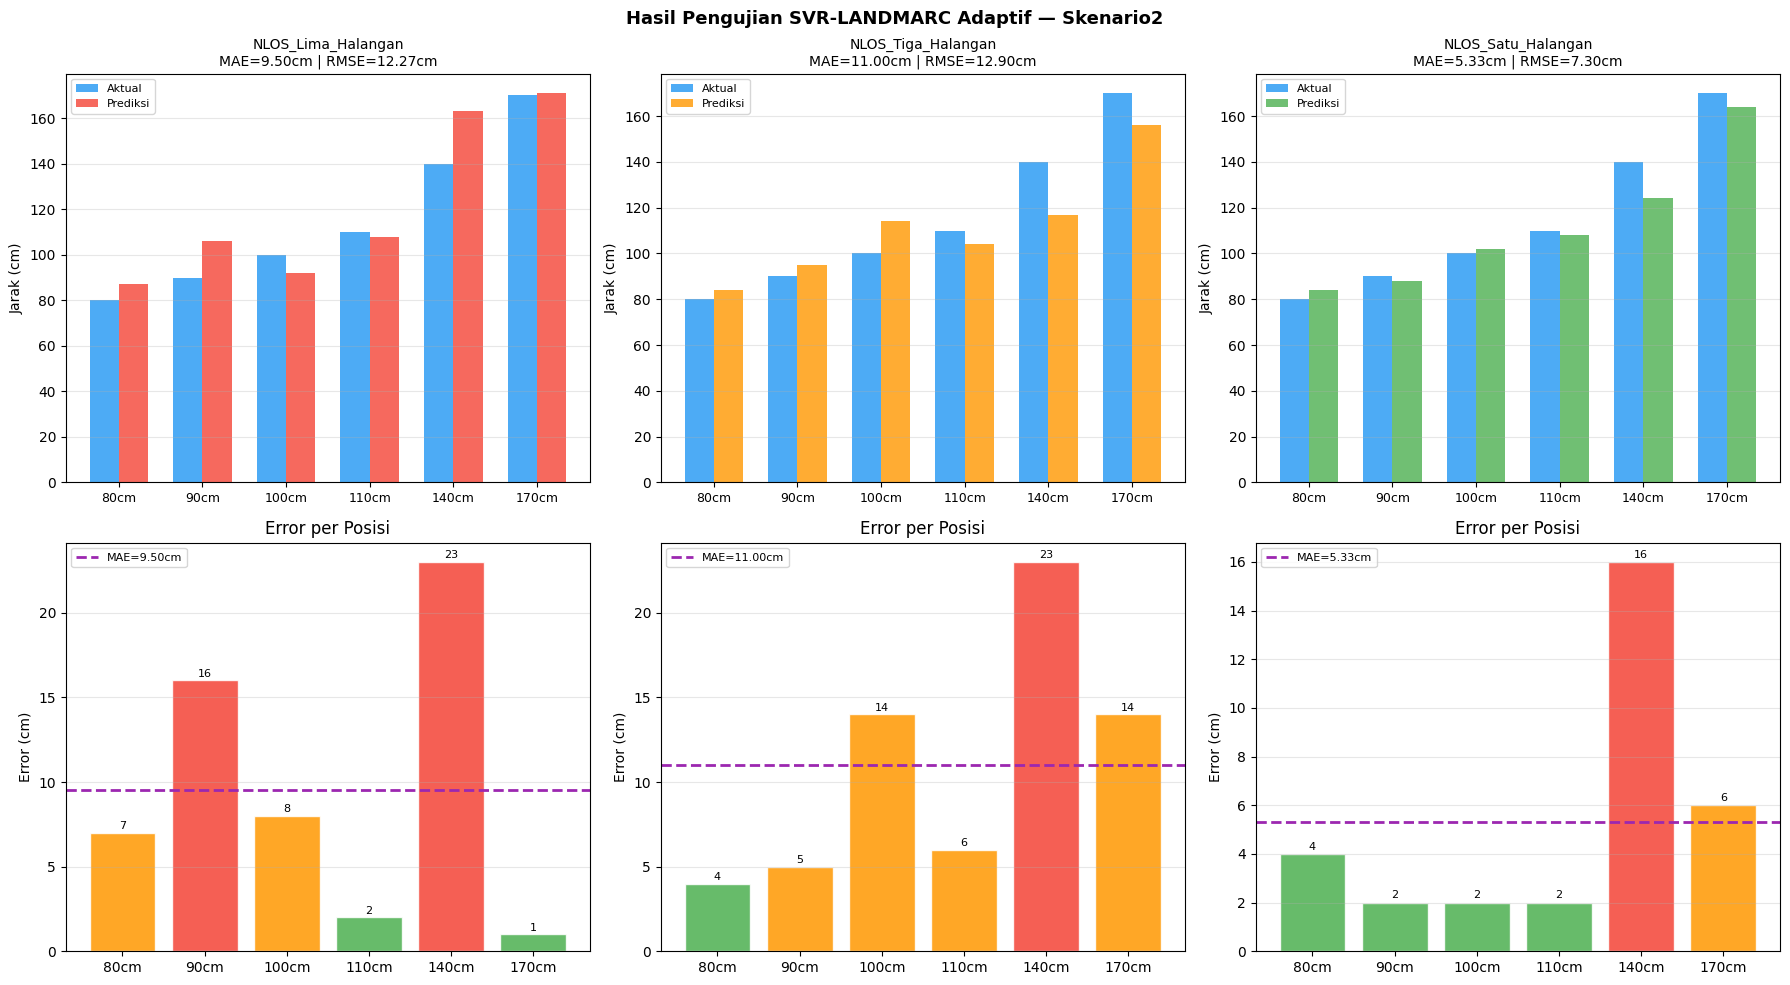

✅ Plot disimpan: adaptasi_nlos_Skenario2.png


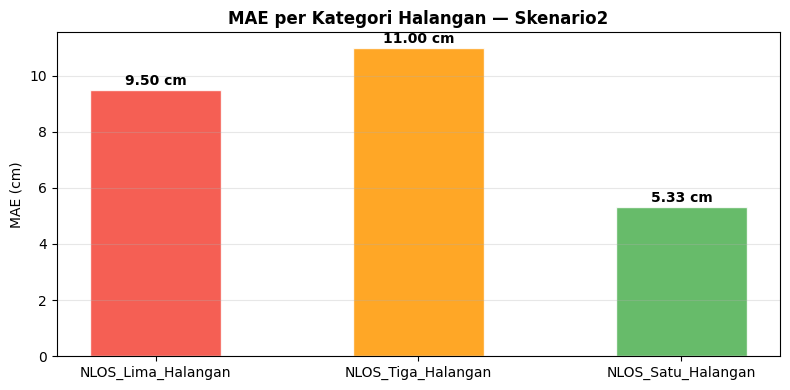

✅ Plot MAE summary disimpan: mae_summary_Skenario2.png


In [21]:
warna_kondisi = {
    "NLOS_Satu_Halangan": "#4CAF50",
    "NLOS_Tiga_Halangan": "#FF9800",
    "NLOS_Lima_Halangan": "#F44336",
}

for skenario, kondisi_dict in hasil_nlos.items():
    if not kondisi_dict:
        continue

    n_kondisi = len(kondisi_dict)
    fig, axes = plt.subplots(
        2, n_kondisi,
        figsize=(6 * n_kondisi, 10),
        squeeze=False
    )

    fig.suptitle(
        f"Hasil Pengujian SVR-LANDMARC Adaptif — {skenario}",
        fontsize=13, fontweight="bold"
    )

    for col, (kondisi, hasil) in enumerate(kondisi_dict.items()):
        records = hasil["hasil_per_target"]
        y_act = np.array([r["jarak_aktual_cm"] for r in records])
        y_pred = np.array([r["jarak_prediksi_cm"] for r in records])
        errors = np.array([r["error_cm"] for r in records])
        x_labels = [f"{int(r['jarak_aktual_cm'])}cm" for r in records]

        # Baris atas — prediksi vs aktual
        ax1 = axes[0, col]
        x_pos = np.arange(len(records))
        width = 0.35
        ax1.bar(
            x_pos - width / 2, y_act, width,
            label="Aktual", color="#2196F3", alpha=0.8
        )
        ax1.bar(
            x_pos + width / 2, y_pred, width,
            label="Prediksi",
            color=warna_kondisi.get(kondisi, "#9E9E9E"),
            alpha=0.8
        )
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(x_labels, fontsize=9)
        ax1.set_title(
            f"{kondisi}\nMAE={hasil['mae_cm']:.2f}cm | "
            f"RMSE={hasil['rmse_cm']:.2f}cm",
            fontsize=10
        )
        ax1.set_ylabel("Jarak (cm)")
        ax1.legend(fontsize=8)
        ax1.grid(True, alpha=0.3, axis="y")

        # Baris bawah — error per posisi
        ax2 = axes[1, col]
        error_colors = [
            "#4CAF50" if error < 5 else "#FF9800" if error < 15 else "#F44336"
            for error in errors
        ]
        bars = ax2.bar(
            x_labels, errors,
            color=error_colors,
            alpha=0.85,
            edgecolor="white"
        )
        ax2.axhline(
            hasil["mae_cm"],
            color="#9C27B0",
            lw=2,
            ls="--",
            label=f"MAE={hasil['mae_cm']:.2f}cm"
        )

        for bar, value in zip(bars, errors):
            ax2.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.1,
                f"{int(value)}",
                ha="center", va="bottom", fontsize=8
            )

        ax2.set_ylabel("Error (cm)")
        ax2.set_title("Error per Posisi")
        ax2.legend(fontsize=8)
        ax2.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()

    fname_plot = f"adaptasi_nlos_{skenario}.png"
    plt.savefig(fname_plot, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Plot disimpan: {fname_plot}")

    # Plot MAE summary
    fig2, ax = plt.subplots(figsize=(8, 4))
    k_labels = list(kondisi_dict.keys())
    mae_vals = [kondisi_dict[k]["mae_cm"] for k in k_labels]
    summary_colors = [warna_kondisi.get(k, "#9E9E9E") for k in k_labels]

    bars = ax.bar(
        k_labels, mae_vals,
        color=summary_colors,
        alpha=0.85,
        edgecolor="white",
        width=0.5
    )

    for bar, value in zip(bars, mae_vals):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{value:.2f} cm",
            ha="center", va="bottom", fontsize=10,
            fontweight="bold"
        )

    ax.set_title(
        f"MAE per Kategori Halangan — {skenario}",
        fontsize=12, fontweight="bold"
    )
    ax.set_ylabel("MAE (cm)")
    ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()

    fname_summary = f"mae_summary_{skenario}.png"
    plt.savefig(fname_summary, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Plot MAE summary disimpan: {fname_summary}")

CELL 10 — SIMPAN HASIL KE EXCEL

In [22]:
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"hasil_adaptasi_nlos_{ts}.xlsx"

wb = Workbook()
wb.remove(wb.active)

ws_sum = wb.create_sheet(title="Ringkasan", index=0)
ws_sum.append([
    "Skenario", "Kondisi", "Jumlah Target",
    "MAE (cm)", "RMSE (cm)", "MAE (m)", "RMSE (m)"
])

for skenario, kondisi_dict in hasil_nlos.items():
    for kondisi, hasil in kondisi_dict.items():
        ws_sum.append([
            skenario,
            kondisi,
            len(hasil["hasil_per_target"]),
            round(hasil["mae_cm"], 2),
            round(hasil["rmse_cm"], 2),
            round(hasil["mae_m"], 4),
            round(hasil["rmse_m"], 4),
        ])

        ws = wb.create_sheet(title=f"{skenario}_{kondisi}"[:31])
        ws.append([
            "No", "Jarak Aktual (cm)", "Vektor Input NLOS",
            "Vektor Koreksi", "Jarak Prediksi (cm)",
            "Error (cm)", "Kondisi", "Skenario"
        ])

        for i, record in enumerate(hasil["hasil_per_target"], 1):
            ws.append([
                i,
                int(record["jarak_aktual_cm"]),
                str(np.round(record["vektor_input"], 4).tolist()),
                str(np.round(record["vektor_koreksi"], 4).tolist()),
                int(record["jarak_prediksi_cm"]),
                int(record["error_cm"]),
                kondisi,
                skenario,
            ])

        ws.append([])
        ws.append(["", "MAE (cm)", round(hasil["mae_cm"], 2)])
        ws.append(["", "RMSE (cm)", round(hasil["rmse_cm"], 2)])

        model_ad = model_adaptif[skenario][kondisi]
        ws_p = wb.create_sheet(title=f"Param_{skenario}_{kondisi}"[:31])
        ws_p.append(["Parameter", "Nilai"])
        ws_p.append(["Metode koreksi", "Weighted Inverse Distance"])
        ws_p.append([])
        ws_p.append([
            "Tag", "xk LOS (dBm)", "xk NLOS (dBm)",
            "ΔRSSI (dBm)", "Jarak Ref (m)"
        ])

        for tag in model_ad["urutan_ref"]:
            ws_p.append([
                tag,
                round(model_ad["xk_los_per_tag"].get(tag, 0), 4),
                round(model_ad["xk_nlos_per_tag"].get(tag, 0), 4),
                round(model_ad["delta_rssi"].get(tag, 0), 5),
                model_ad["jarak_ref_per_tag"].get(tag, "-"),
            ])

for ws in wb.worksheets:
    for col in ws.columns:
        width = max((len(str(cell.value or "")) for cell in col), default=0)
        ws.column_dimensions[col[0].column_letter].width = min(width + 4, 35)

wb.save(filename)
files.download(filename)

print(f"✅ Hasil disimpan dan didownload: {filename}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Hasil disimpan dan didownload: hasil_adaptasi_nlos_20260930_174223.xlsx


CELL 11 — SIMPAN MODEL ADAPTIF KE JSON

In [23]:
def simpan_model_adaptif(model_adaptif: dict) -> str:
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"model_adaptif_nlos_{ts}.json"
    output = {}

    for skenario, kondisi_dict in model_adaptif.items():
        output[skenario] = {}

        for kondisi, model in kondisi_dict.items():
            output[skenario][kondisi] = {
                "gamma": model["gamma"],
                "C": model["C"],
                "epsilon": model["epsilon"],
                "b": model["b"],
                "alpha_diff": model["alpha_diff"].tolist(),
                "X_train": model["X_train"].tolist(),
                "y_train": model["y_train"].tolist(),
                "urutan_ref": model["urutan_ref"],
                "n_fitur": model["n_fitur"],
                "delta_rssi": model["delta_rssi"],
                "xk_los_per_tag": model["xk_los_per_tag"],
                "jarak_ref_per_tag": model["jarak_ref_per_tag"],
                "implementasi": "SVR_manual_adaptif_weighted",
            }

    with open(filename, "w") as f:
        json.dump(output, f, indent=2)

    print(f"✅ Model adaptif disimpan: {filename}")
    return filename


json_adaptif = simpan_model_adaptif(model_adaptif)
files.download(json_adaptif)

print("✅ JSON model adaptif didownload.")

✅ Model adaptif disimpan: model_adaptif_nlos_20260930_174227.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ JSON model adaptif didownload.


CELL 12 — RINGKASAN AKHIR

In [24]:
print("\n" + "=" * 60)
print("  RINGKASAN HASIL ADAPTASI DAN PENGUJIAN NLOS")
print("=" * 60)

for skenario, kondisi_dict in hasil_nlos.items():
    print(f"\n📋 {skenario}:")
    print(f"  {'Kondisi':<24} {'MAE (cm)':>10} {'RMSE (cm)':>11}")
    print(f"  {'-' * 24} {'-' * 10} {'-' * 11}")

    for kondisi, hasil in kondisi_dict.items():
        print(
            f"  {kondisi:<24} "
            f"{hasil['mae_cm']:>10.2f} "
            f"{hasil['rmse_cm']:>11.2f}"
        )

print("\n" + "=" * 60)
print("  ✅ Adaptasi dan pengujian NLOS selesai!")
print("=" * 60)


  RINGKASAN HASIL ADAPTASI DAN PENGUJIAN NLOS

📋 Skenario2:
  Kondisi                    MAE (cm)   RMSE (cm)
  ------------------------ ---------- -----------
  NLOS_Lima_Halangan             9.50       12.27
  NLOS_Tiga_Halangan            11.00       12.90
  NLOS_Satu_Halangan             5.33        7.30

  ✅ Adaptasi dan pengujian NLOS selesai!
